In [8]:
#Import the libary 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectFromModel, mutual_info_classif
from sklearn.metrics import classification_report, roc_auc_score, mean_absolute_error, r2_score
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [9]:
#Read the file 
online_shoppers_cleaned=pd.read_csv("/Users/jahaankachwala/Downloads/Projects /Online Retail/online_shoppers_cleaned.csv")
online_shoppers_intention=pd.read_csv("/Users/jahaankachwala/Downloads/Projects /Online Retail/online_shoppers_intention.csv")

In [11]:
#Basic checks 
print("Retail Check:",online_shoppers_cleaned.shape)
print("Intention Shape:",online_shoppers_intention.shape) 

Retail Check: (541909, 8)
Intention Shape: (12330, 18)


In [13]:
#Mean, median, mode and descriptive statistics for Intention
print("\nIntention Data-Descriptive stats")
print(online_shoppers_intention.describe(include="all").T)
print("n\Mode",online_shoppers_intention.mode())


Intention Data-Descriptive stats
                           count unique                top   freq        mean  \
Administrative           12330.0    NaN                NaN    NaN    2.315166   
Administrative_Duration  12330.0    NaN                NaN    NaN   80.818611   
Informational            12330.0    NaN                NaN    NaN    0.503569   
Informational_Duration   12330.0    NaN                NaN    NaN   34.472398   
ProductRelated           12330.0    NaN                NaN    NaN   31.731468   
ProductRelated_Duration  12330.0    NaN                NaN    NaN  1194.74622   
BounceRates              12330.0    NaN                NaN    NaN    0.022191   
ExitRates                12330.0    NaN                NaN    NaN    0.043073   
PageValues               12330.0    NaN                NaN    NaN    5.889258   
SpecialDay               12330.0    NaN                NaN    NaN    0.061427   
Month                      12330     10                May   3364         N

In [14]:
#Mean, median, mode and online_shoppers_cleaned
print("\nRETAIL DATA — DESCRIPTIVE STATISTICS")
print(online_shoppers_cleaned.describe(include="all").T)

retail_numeric = online_shoppers_cleaned.select_dtypes(include=np.number)
print("\nRetail means:\n", retail_numeric.mean())
print("\nRetail medians:\n", retail_numeric.median())
print("\nRetail modes:\n", retail_numeric.mode().iloc[0])


RETAIL DATA — DESCRIPTIVE STATISTICS
                count unique                                 top    freq  \
InvoiceNo      541909  25900                              573585    1114   
StockCode      541909   4070                              85123A    2313   
Description    541909   4212  WHITE HANGING HEART T-LIGHT HOLDER    2369   
Quantity     541909.0    NaN                                 NaN     NaN   
InvoiceDate    541909  23260                 2011-10-31 14:41:00    1114   
UnitPrice    541909.0    NaN                                 NaN     NaN   
CustomerID   541909.0    NaN                                 NaN     NaN   
Country        541909     38                      United Kingdom  495478   

                     mean          std       min      25%      50%      75%  \
InvoiceNo             NaN          NaN       NaN      NaN      NaN      NaN   
StockCode             NaN          NaN       NaN      NaN      NaN      NaN   
Description           NaN          NaN  

In [15]:
#Clean retail data and calculate sales
retail = online_shoppers_cleaned.copy()
retail["InvoiceDate"] = pd.to_datetime(retail["InvoiceDate"], errors="coerce")
retail["Sales"] = retail["Quantity"] * retail["UnitPrice"]

# Exclude cancellations, returns and non-positive prices from positive-sales analysis
retail_sales = retail[
    (~retail["InvoiceNo"].astype(str).str.startswith("C")) &
    (retail["Quantity"] > 0) &
    (retail["UnitPrice"] > 0)
].copy()

print("\nGross positive line sales:", retail_sales["Sales"].sum())


Gross positive line sales: 10666684.544


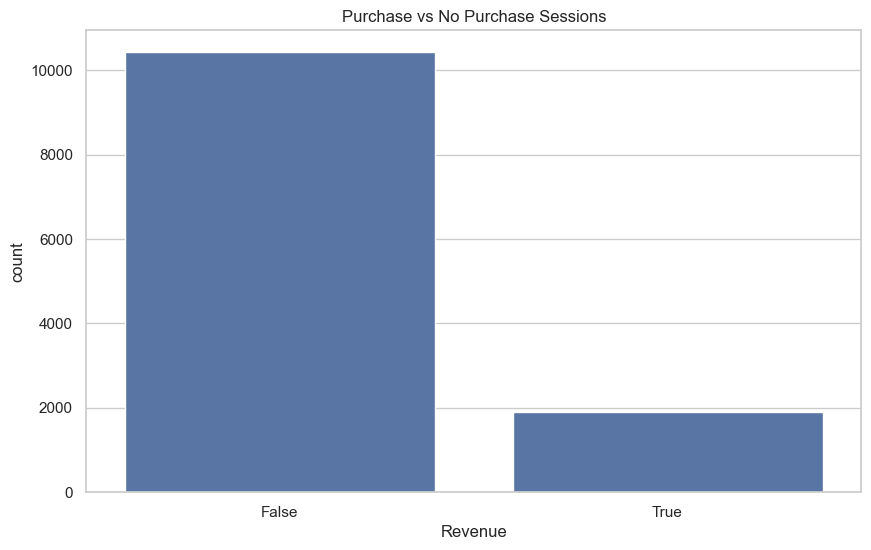

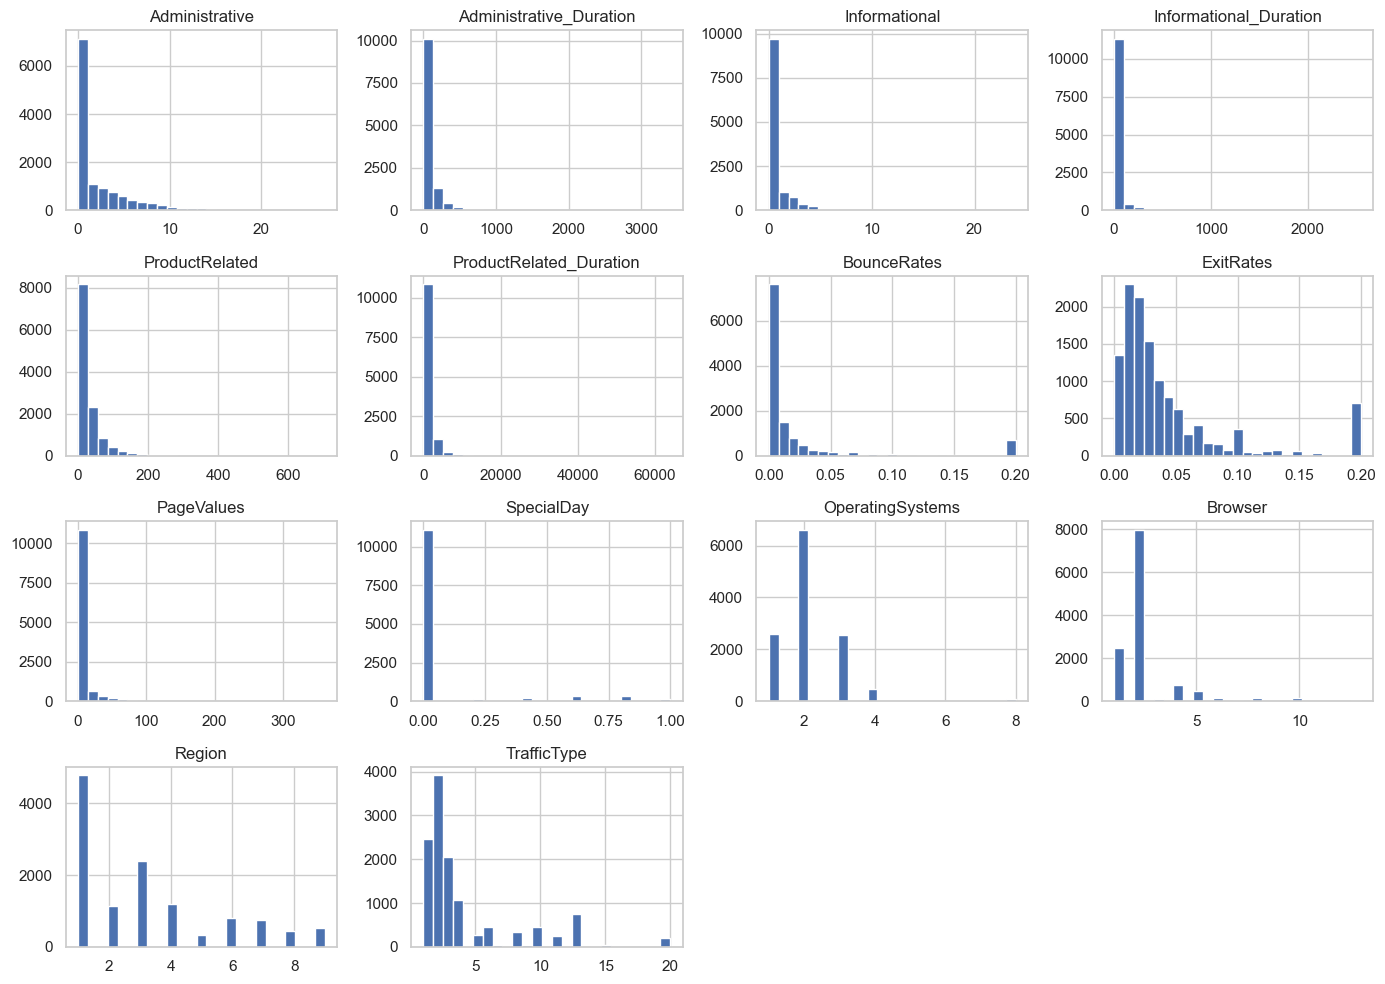

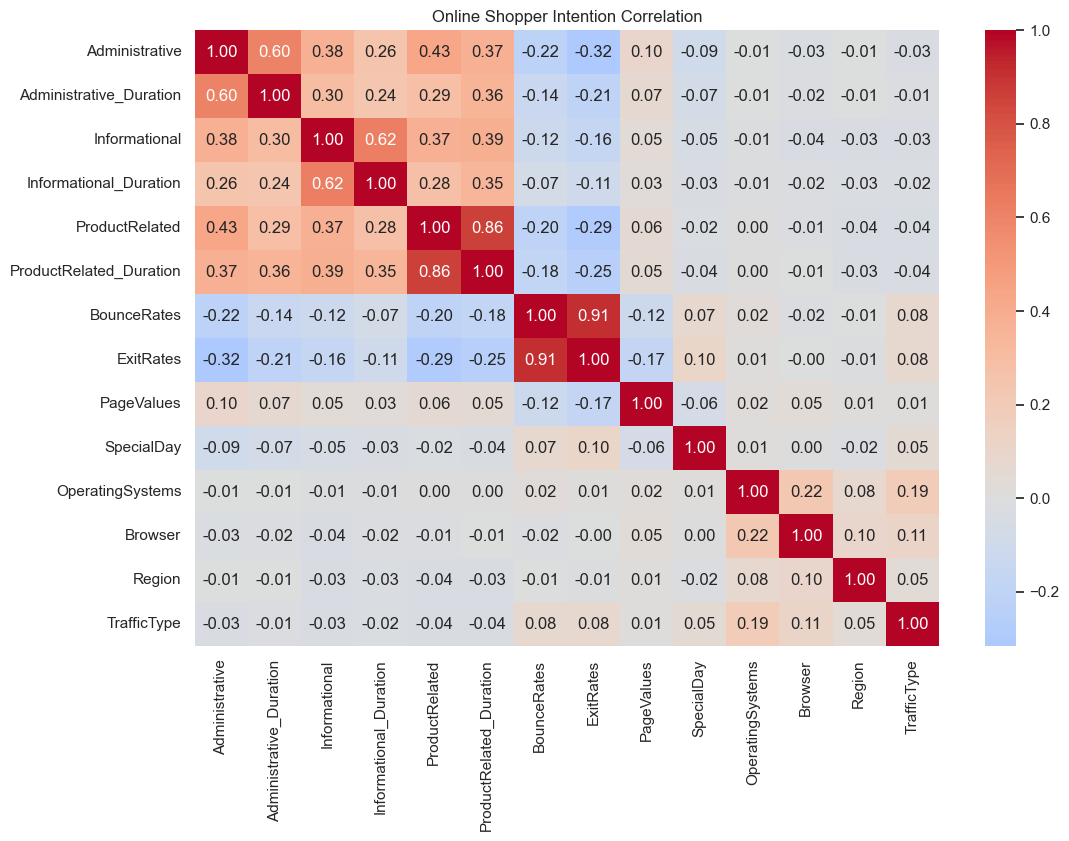

In [16]:
#Plots — purchase outcome and numeric distributions
sns.set_theme(style="whitegrid")

sns.countplot(data=online_shoppers_intention, x="Revenue")
plt.title("Purchase vs No Purchase Sessions")
plt.show()

online_shoppers_intention.select_dtypes(include=np.number).hist(figsize=(14, 10), bins=25)
plt.tight_layout()
plt.show()

# Correlation heatmap for intention data
intention_numeric = online_shoppers_intention.select_dtypes(include=np.number)
plt.figure(figsize=(12, 8))
sns.heatmap(intention_numeric.corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Online Shopper Intention Correlation")
plt.show()

In [17]:
#Purchase-intent classification
X = online_shoppers_intention.drop(columns="Revenue").copy()
y = online_shoppers_intention["Revenue"].astype(int)

# Convert Boolean/categorical columns for preprocessing
for col in X.select_dtypes(include=["bool"]).columns:
    X[col] = X[col].astype(str)

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

purchase_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200, random_state=42,
        class_weight="balanced", min_samples_leaf=3
    ))
])

purchase_model.fit(X_train, y_train)
predictions = purchase_model.predict(X_test)
probabilities = purchase_model.predict_proba(X_test)[:, 1]

print("\nPURCHASE CLASSIFICATION")
print(classification_report(y_test, predictions, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, probabilities), 3))


PURCHASE CLASSIFICATION
              precision    recall  f1-score   support

           0       0.94      0.93      0.94      2084
           1       0.64      0.70      0.67       382

    accuracy                           0.89      2466
   macro avg       0.79      0.81      0.80      2466
weighted avg       0.90      0.89      0.90      2466

ROC-AUC: 0.926



TOP PURCHASE DRIVERS
                         Feature  Importance
8                num__PageValues    0.426247
7                 num__ExitRates    0.096463
5   num__ProductRelated_Duration    0.083267
4            num__ProductRelated    0.063163
6               num__BounceRates    0.056938
1   num__Administrative_Duration    0.044297
0            num__Administrative    0.035354
21                cat__Month_Nov    0.029318
13              num__TrafficType    0.021844
12                   num__Region    0.021271
3    num__Informational_Duration    0.018299
2             num__Informational    0.012046
20                cat__Month_May    0.011609
11                  num__Browser    0.011216
10         num__OperatingSystems    0.011098


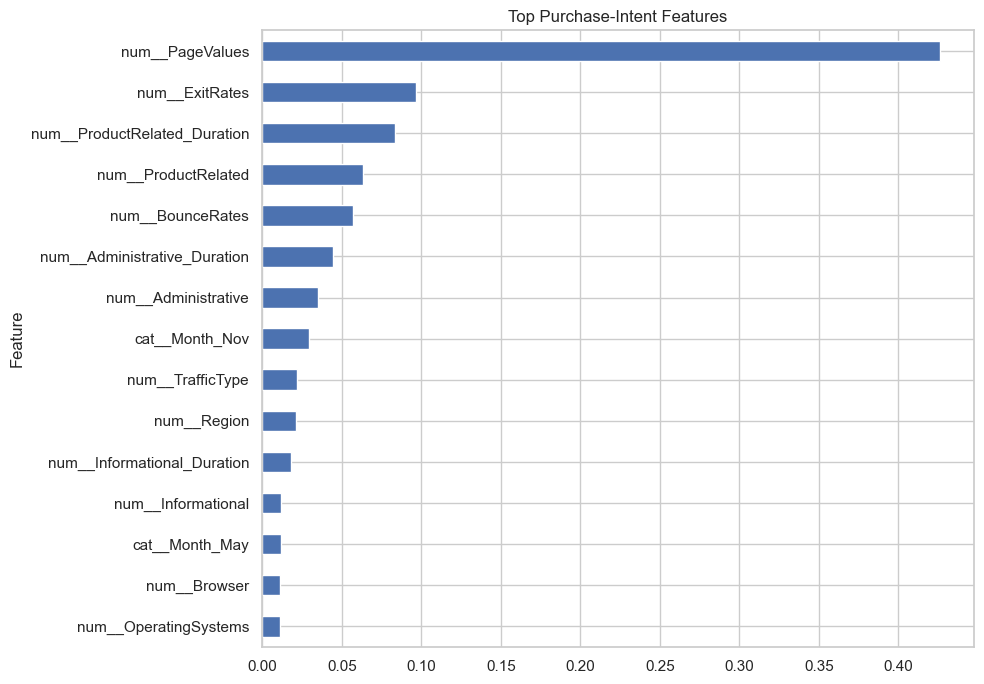


Selected features:
['num__Administrative' 'num__Administrative_Duration' 'num__Informational'
 'num__Informational_Duration' 'num__ProductRelated'
 'num__ProductRelated_Duration' 'num__BounceRates' 'num__ExitRates'
 'num__PageValues' 'num__OperatingSystems' 'num__Browser' 'num__Region'
 'num__TrafficType' 'cat__Month_May' 'cat__Month_Nov']

TOP FEATURES BY MUTUAL INFORMATION
                         Feature  MutualInformation
8                num__PageValues           0.169476
5   num__ProductRelated_Duration           0.038508
7                 num__ExitRates           0.037914
6               num__BounceRates           0.023900
4            num__ProductRelated           0.020578
0            num__Administrative           0.016863
1   num__Administrative_Duration           0.015515
13              num__TrafficType           0.011821
21                cat__Month_Nov           0.011788
9                num__SpecialDay           0.009400


In [18]:
# Feature importance and feature selection
feature_names = purchase_model.named_steps["preprocess"].get_feature_names_out()
importance = purchase_model.named_steps["model"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

print("\nTOP PURCHASE DRIVERS")
print(feature_importance.head(15))

feature_importance.head(15).sort_values("Importance").plot(
    kind="barh", x="Feature", y="Importance", legend=False, figsize=(10, 7)
)
plt.title("Top Purchase-Intent Features")
plt.tight_layout()
plt.show()

selector = SelectFromModel(
    purchase_model.named_steps["model"], threshold="median", prefit=True
)
print("\nSelected features:")
print(feature_names[selector.get_support()])

# Mutual information — captures non-linear relationships
X_train_encoded = purchase_model.named_steps["preprocess"].transform(X_train)
mi_scores = mutual_info_classif(X_train_encoded, y_train, random_state=42)
mi_table = pd.DataFrame({
    "Feature": feature_names,
    "MutualInformation": mi_scores
}).sort_values("MutualInformation", ascending=False)

print("\nTOP FEATURES BY MUTUAL INFORMATION")
print(mi_table.head(10))

In [19]:
#Simple regression to estimate transaction-line sales
# Sales is mathematically Quantity * UnitPrice, so interpret this as prediction, not causation.
regression_data = retail_sales[["Quantity", "UnitPrice", "Sales"]].dropna()
regression_data = regression_data.sample(
    min(30000, len(regression_data)), random_state=42
)

X_reg = regression_data[["Quantity", "UnitPrice"]]
y_reg = regression_data["Sales"]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

sales_model = RandomForestRegressor(
    n_estimators=100, random_state=42, min_samples_leaf=3
)
sales_model.fit(Xr_train, yr_train)
sales_predictions = sales_model.predict(Xr_test)

print("\nRETAIL SALES REGRESSION")
print("MAE:", round(mean_absolute_error(yr_test, sales_predictions), 2))
print("R-squared:", round(r2_score(yr_test, sales_predictions), 3))



RETAIL SALES REGRESSION
MAE: 6.14
R-squared: -2.89


In [20]:
#Customer clustering (RFM-style)
customer_data = retail_sales.dropna(subset=["CustomerID"]).groupby("CustomerID").agg(
    Monetary=("Sales", "sum"),
    Frequency=("InvoiceNo", "nunique"),
    Units=("Quantity", "sum"),
    ProductVariety=("StockCode", "nunique"),
    LastPurchase=("InvoiceDate", "max")
).reset_index()

reference_date = retail_sales["InvoiceDate"].max() + pd.Timedelta(days=1)
customer_data["RecencyDays"] = (
    reference_date - customer_data["LastPurchase"]
).dt.days

cluster_cols = ["Monetary", "Frequency", "Units", "ProductVariety", "RecencyDays"]
cluster_X = customer_data[cluster_cols].replace([np.inf, -np.inf], np.nan)
cluster_X = cluster_X.fillna(cluster_X.median())

# Reduce extreme-value influence before scaling
cluster_X = cluster_X.clip(
    lower=cluster_X.quantile(0.01),
    upper=cluster_X.quantile(0.99),
    axis=1
)
cluster_scaled = StandardScaler().fit_transform(cluster_X)

scores = {}
for k in range(2, 6):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(cluster_scaled)
    sample_idx = np.random.RandomState(42).choice(
        len(cluster_scaled), min(5000, len(cluster_scaled)), replace=False
    )
    scores[k] = silhouette_score(cluster_scaled[sample_idx], labels[sample_idx])

best_k = max(scores, key=scores.get)
customer_data["Cluster"] = KMeans(
    n_clusters=best_k, random_state=42, n_init=10
).fit_predict(cluster_scaled)

print("\nSilhouette scores:", scores)
print("Selected number of clusters:", best_k)
print("\nCustomer cluster profiles:")
print(customer_data.groupby("Cluster")[cluster_cols].mean().round(2))


Silhouette scores: {2: 0.6369901742471873, 3: 0.4208568221586428, 4: 0.4516167520415796, 5: 0.42295795261295144}
Selected number of clusters: 2

Customer cluster profiles:
         Monetary  Frequency    Units  ProductVariety  RecencyDays
Cluster                                                           
0          932.16       2.85   549.40           46.37       100.15
1        17244.87      21.55  8443.64          215.91        18.80


In [22]:
#Save useful results
feature_importance.to_csv("purchase_feature_importance.csv", index=False)
mi_table.to_csv("purchase_mutual_information.csv", index=False)
monthly_sales.to_csv("monthly_sales.csv", index=False)
customer_data.to_csv("customer_clusters.csv", index=False)

print("\nAnalysis complete. Result CSV files saved in your current working directory.")



Analysis complete. Result CSV files saved in your current working directory.
